# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.Fm Logistic Regression Notebook
*By Mark Lambert - C00192497*

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 13th October 2026*

---

This notebook runs a ```Logistic Regression``` on the Last.Fm scrobble data. 

The goal of the model is to predict what artist I am more likely to listen to on a given time of day, selected from my top 10 artists based on the number of entries that artist has in the dataset.

```%pip install pandas scikit-learn matplotlib```

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LinearRegression
scrobbles = pd.read_csv('datasets/scrobbles.csv')

To get my top 10 artists, we can query the dataset by taking a total count per artist and slect the top 10

In [3]:
top_artists = scrobbles['artist'].value_counts().head(10).index
subset = scrobbles[scrobbles['artist'].isin(top_artists)].copy()

print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2230
Tame Impala              2042
Red Hot Chili Peppers    1559
Portishead               1199
Alice in Chains          1108
John Mayer                892
Ghost                     572
Morcheeba                 562
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

A Logistic Regression is then run to predict which artist from my Top 10 artists I'm likely to listen to given the time of day

Feature used: tod - The time of day I listened to a track

In [10]:
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.19955257270693513
Model accuracy: 0.23355704697986576
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       222
       Arctic Monkeys       0.23      0.57      0.33       446
                Ghost       0.00      0.00      0.00       114
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       102
           Portishead       0.00      0.00      0.00       240
Red Hot Chili Peppers       0.00      0.00      0.00       312
          Tame Impala       0.23      0.65      0.34       409

             accuracy                           0.23      2235
            macro avg       0.05      0.12      0.07      2235
         weighted avg       0.09      0.23      0.13      2235



A ```Logistic Regression``` is then run to predict which ```artist``` from my Top 10 artists I'm likely to listen to given the **time of day**

Feature used: ```tod``` - The time of day I listened to a track

           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.12            0.11   0.10        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.27   0.01        0.14            0.02   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.14                   0.14   
night           0.10        0.09        0.10                   0.04   

           Tame Impala  
morning           0.31  
afternoon         0.21  
evening           0.13  
night             0.17  


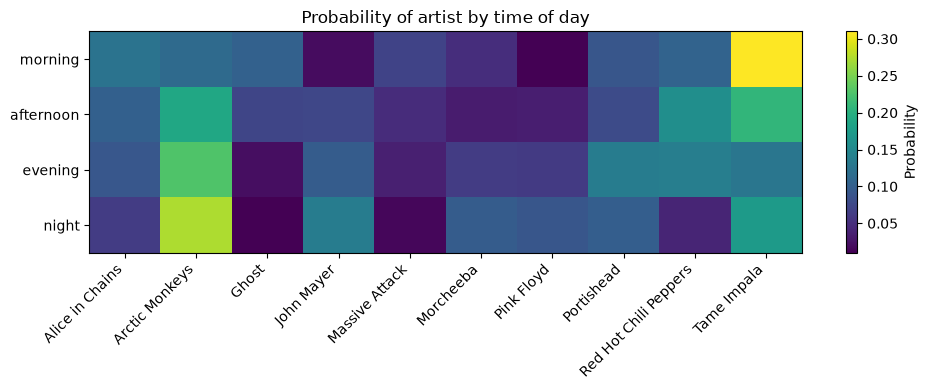

In [11]:
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(clf.predict_proba(buckets), columns=clf.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

Tame Impala AUC: 0.628
Odds ratio per hour: 0.894


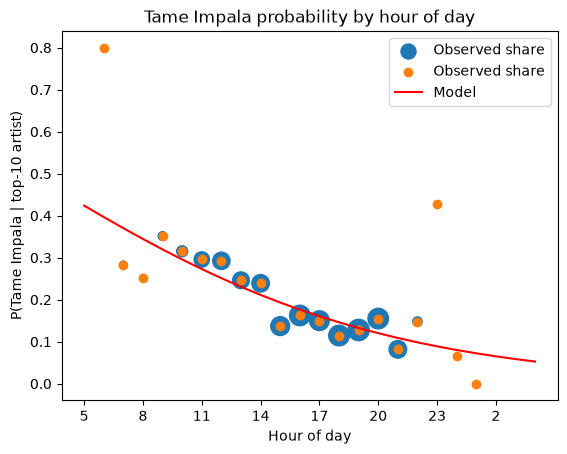

In [13]:
subset['hours_since_5'] = (subset['hour'] - 5) % 24
def artist_hour_model(artist_name):
    # Binary logistic regression: is this scrobble the chosen artist, given the hour
    data = subset.copy()
    data['is_target'] = (data['artist'] == artist_name).astype(int)

    X = data[['hours_since_5']]
    y = data['is_target']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(artist_name, 'AUC:', round(auc, 3))
    print('Odds ratio per hour:', np.exp(model.coef_[0][0]).round(3))

    hrs = np.arange(0, 24)
    curve = model.predict_proba(pd.DataFrame({'hours_since_5': hrs}))[:, 1]
    observed = data.groupby('hours_since_5')['is_target'].mean()
    counts = data.groupby('hours_since_5').size()
    plt.scatter(observed.index, observed.values, s=counts.loc[observed.index] / 5, label='Observed share')
    plt.scatter(observed.index, observed.values, label='Observed share')
    plt.plot(hrs, curve, color='red', label='Model')
    plt.xticks(range(0, 24, 3), [(h + 5) % 24 for h in range(0, 24, 3)])
    plt.xlabel('Hour of day')
    plt.ylabel(f'P({artist_name} | top-10 artist)')
    plt.title(f'{artist_name} probability by hour of day')
    plt.legend()
    plt.show()

artist_hour_model('Tame Impala')